In [77]:
import pandas as pd
import matplotlib.pyplot as plt

filename = r"exoplanets_slim_2026-11-3.csv"

df = pd.read_csv(
    filename,
    header=0
)

# making columns titles more readable
df = df.rename(columns={
    "pl_name": "pl_name",
    "hostname": "host_name",

    "sy_snum": "sys_num_star",
    "sy_pnum": "sys_num_planet",
    "sy_dist": "sys_dist_e",

    "discoverymethod": "disc_method",
    #"disc_year": "",
    #"disc_facility": "",

    #"pl_controv_flag": "",
    "pl_eqt": "pl_temp",
    "pl_insol": "pl_insol_flux",

    "pl_orbper": "pl_orb_period",
    "pl_orbeccen": "pl_orb_eccen",
    "pl_orbsmax": "pl_orb_semimajor_axis",

    "pl_rade": "pl_radius_e",
    "pl_bmasse": "pl_mass_e",
    "pl_bmassprov": "pl_mass_prov",

    "st_teff": "st_temp",
    "st_rad": "st_radius",
    #"st_mass": "",
    "st_met": "st_metal",
    "st_logg": "st_gravity",
    #"st_age": "",
    })

print(df.shape)
display(df.dtypes)

(6451, 23)


pl_name                      str
host_name                    str
sys_num_star               int64
sys_num_planet             int64
sys_dist_e               float64
disc_method                  str
disc_year                  int64
disc_facility                str
pl_controv_flag            int64
pl_temp                  float64
pl_insol_flux            float64
pl_orb_period            float64
pl_orb_eccen             float64
pl_orb_semimajor_axis    float64
pl_radius_e              float64
pl_mass_e                float64
pl_mass_prov                 str
st_temp                  float64
st_radius                float64
st_mass                  float64
st_metal                 float64
st_gravity               float64
st_age                   float64
dtype: object

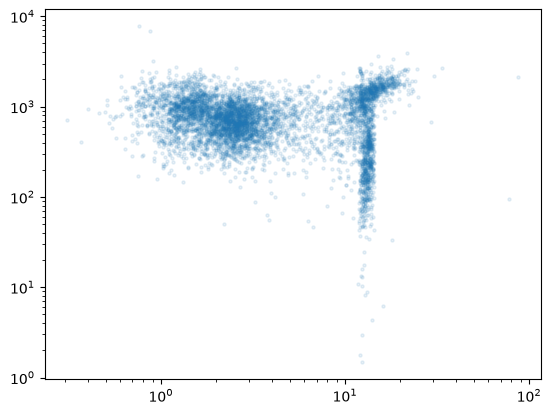

In [74]:
x = df["pl_radius_e"]
y = df["pl_temp"]

p = plt.figure()
plt.yscale("log")
plt.xscale("log")
plt.scatter(x, y, alpha=0.1, s=5)

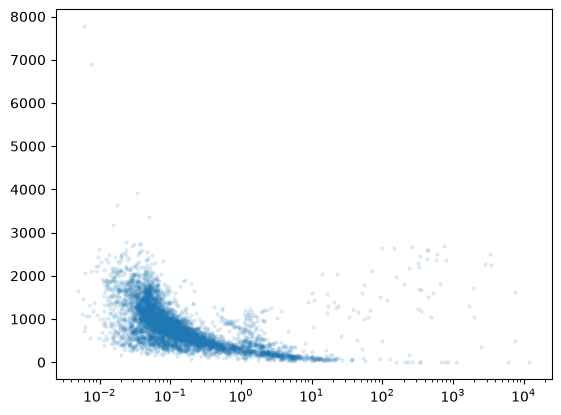

In [79]:
# removeOutliers = df["pl_orb_semimajor_axis"] < 1.0
# d = df[removeOutliers]
x = df["pl_orb_semimajor_axis"]
y = df["pl_temp"]

p = plt.figure()
plt.xscale("log")
plt.scatter(x, y, alpha=0.1, s=5)

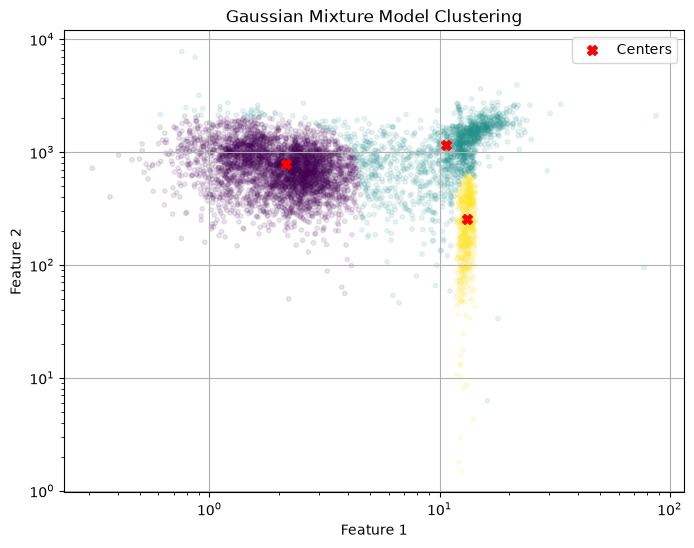

In [111]:
import numpy as np
from sklearn.mixture import GaussianMixture

d = df[["pl_radius_e", "pl_temp"]].dropna()

# Select both features for the 2D GMM tracking
X = d[["pl_radius_e", "pl_temp"]].values  # .values converts it to a numpy array for easy slicing

y = d["pl_temp"]

gmm = GaussianMixture(
    n_components=3,
    covariance_type='full',
    random_state=42
)

gmm.fit(X)               
labels = gmm.predict(X)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=10, alpha=0.1)

plt.scatter(
    gmm.means_[:, 0],
    gmm.means_[:, 1],
    s=50,
    c='red',
    marker='X',
    label='Centers'
)

plt.title("Gaussian Mixture Model Clustering")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.legend()
plt.show()